# Zomato Data Analysis

# Project Overview
This project analyzes Zomato restaurant data to understand
restaurant preferences, customer ratings, online ordering behavior,
restaurant popularity, and approximate dining costs.

The project uses Python for data cleaning, exploratory data analysis and visualization.

# Phase-I
# Step 1: Import Libraries
1) Pandas used for data manipulation, analysis, and working with structured data.
2) NumPy stands for Numerical Python. It is a Python library used mainly for numerical calculations and working with arrays.
3) Matplotlib is a Python library used to create graphs and visualizations.
   pyplot is a module inside Matplotlib that provides functions for creating charts.
4) Seaborn is a Python library used for data visualization. It is built on top of Matplotlib and makes it easier to create attractive statistical graphs.

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Load the Dataset
1) A DataFrame is basically a table containing rows and columns.
   Pandas stores this table as a DataFrame.
2) read.csv() is used to read the csv file.

In [66]:
df = pd.read_csv("../data/raw/Zomato-data.csv")

# Step 3: View the Dataset
1) head() is used to show/print first 5 rows

In [67]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


# Step 4: Find the Number of Rows and Columns
shape gives number of (rows,columns)

In [68]:
df.shape

(148, 7)

# Step 5: See Column Names

In [69]:
df.columns

Index(['name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')

# Step 6: Check Data Types

In [70]:
df.dtypes

name                             str
online_order                     str
book_table                       str
rate                             str
votes                          int64
approx_cost(for two people)    int64
listed_in(type)                  str
dtype: object

# Step 7: Get Complete Dataset Information
1) info() gives the information of the dataset
   like no.of rows, no.of columns, non-null values, data types and memory usage

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   name                         148 non-null    str  
 1   online_order                 148 non-null    str  
 2   book_table                   148 non-null    str  
 3   rate                         148 non-null    str  
 4   votes                        148 non-null    int64
 5   approx_cost(for two people)  148 non-null    int64
 6   listed_in(type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 8.2 KB


# Step 8: Check Missing Values
1) isnull() used to check whether a value is missing.
2) sum() used to count, how many values are missing.

In [72]:
df.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

# Step 9: Check Duplicate Rows

In [73]:
df.duplicated().sum()

np.int64(0)

# Step 10: Statistical Summary

In [74]:
df.describe()

,votes,approx_cost(for two people)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


# Phase-II
# DATA CLEANING

# Step 1: Make a Copy of the Data
1) We will perform data cleaning in newly created copy of the data set, rather than raw data set.

In [75]:
cleaned_df = df.copy()

# Step 2: Look at the Rating Column

In [76]:
cleaned_df['rate'].head(10)

0    4.1/5
1    4.1/5
2    3.8/5
3    3.7/5
4    3.8/5
5    3.8/5
6    3.6/5
7    4.6/5
8    4.0/5
9    4.2/5
Name: rate, dtype: str

# Step 3: Clean the Entire Rate Column
1) Here we split the "4.1/5" rating value which is string data type into 2 values.
2) They are ["4.1", "5"] as [0], [1].
3) str[0] means "4.1" and str[1] means "5"

In [77]:
cleaned_df['rate'] = cleaned_df['rate'].str.split('/').str[0]

# Step 4: Convert the Rating to a Number
1) After splitting the rating values, still they are string data type.
2) So, in this step we are converting them into float values.

In [78]:
cleaned_df['rate'] = cleaned_df['rate'].astype(float)

# Step 5: Verify the rate column

In [79]:
cleaned_df['rate'].head(10)

0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
5    3.8
6    3.6
7    4.6
8    4.0
9    4.2
Name: rate, dtype: float64

# Step 6.1 — Check online_order
1) unique() gives us the different values present in that column.

In [80]:
cleaned_df['online_order'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

# Step 6.2: Count Online Order Values
1) value_counts() tells us how many restaurants belong to each category.

In [81]:
cleaned_df['online_order'].value_counts()

online_order
No     90
Yes    58
Name: count, dtype: int64

# Step 6.3: Check book_table

In [82]:
cleaned_df['book_table'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

# Step 6.4: Count Book Table Values

In [83]:
cleaned_df['book_table'].value_counts()

book_table
No     140
Yes      8
Name: count, dtype: int64

# Step 6.5: Check Restaurant Types(listed_in(type))

In [84]:
cleaned_df['listed_in(type)'].unique()

<StringArray>
['Buffet', 'Cafes', 'other', 'Dining']
Length: 4, dtype: str

# Step 6.6: Count Restuarant Types(listed_in(type)) Values

In [85]:
cleaned_df['listed_in(type)'].value_counts()

listed_in(type)
Dining    110
Cafes      23
other       8
Buffet      7
Name: count, dtype: int64

# Step 6.7: Check Votes

In [86]:
# min() gives us minimum value in that column.
cleaned_df['votes'].min()

np.int64(0)

In [87]:
# max() gives us maximum value in that column.
cleaned_df['votes'].max()

np.int64(4884)

In [88]:
# mean() gives us average/mean of that column values.
cleaned_df['votes'].mean()

np.float64(264.81081081081084)

In [89]:
# Chech for in-valid votes
cleaned_df[cleaned_df['votes'] < 0]

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)


No negative vote values were found, so the votes column does not require cleaning.

# Step 7: Check Approximate Cost

In [90]:
# Checking unique values in the column
cleaned_df['approx_cost(for two people)'].unique()

array([800, 300, 600, 700, 550, 500, 450, 650, 400, 900, 200, 750, 150,
       850, 100, 350, 250, 950])

In [91]:
# value_counts() gives us the count of each value occured how may times
# sort_index() gives us the largest to smallest of the values occured
cleaned_df['approx_cost(for two people)'].value_counts().sort_index()

approx_cost(for two people)
100     6
150    16
200    16
250     6
300    23
350     3
400    15
450     6
500    14
550     3
600    13
650     2
700     5
750     3
800    12
850     2
900     2
950     1
Name: count, dtype: int64

In [92]:
# min() gives us minimum value in that column
cleaned_df['approx_cost(for two people)'].min()

np.int64(100)

In [93]:
# max() gives us maximum value in that column
cleaned_df['approx_cost(for two people)'].max()

np.int64(950)

In [94]:
# Check for in-valid values
cleaned_df[cleaned_df['approx_cost(for two people)'] < 0]

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)


No negative cost values were found, so the approx_cost(for two people) column does not require cleaning.

# Data Check up
# Step 8.1: Check the Complete Cleaned Dataset

In [95]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 8.2 KB


# Step 8.2: Check Missing Values Again

In [96]:
cleaned_df.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

# Step 8.3: Check Duplicate Rows Again

In [97]:
cleaned_df.duplicated().sum()

np.int64(0)

# Step 8.4: Check the Final Shape

In [98]:
cleaned_df.shape

(148, 7)

# Step 8.5: Check Rate column Data Type

In [99]:
cleaned_df['rate'].dtype

dtype('float64')

# Step 9: Save the Cleaned DataSet

In [100]:
cleaned_df.to_csv(
    "../data/cleaned/cleaned_zomato.csv",
    index=False
)

In [101]:
# Verify
check_df = pd.read_csv("../data/cleaned/cleaned_zomato.csv")

In [102]:
check_df.shape

(148, 7)

# Phase-III
# Exploratory Data Analysis

### Step 1: Load the Cleaned Dataset

In [103]:
eda_df = pd.read_csv("../data/cleaned/cleaned_zomato.csv")

In [104]:
# Number of rows and columns
eda_df.shape

(148, 7)

In [105]:
# View the Dataset
eda_df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


# Answering Business Questions

## 1) What types of restaurants are present in the dataset, and which type is most common?

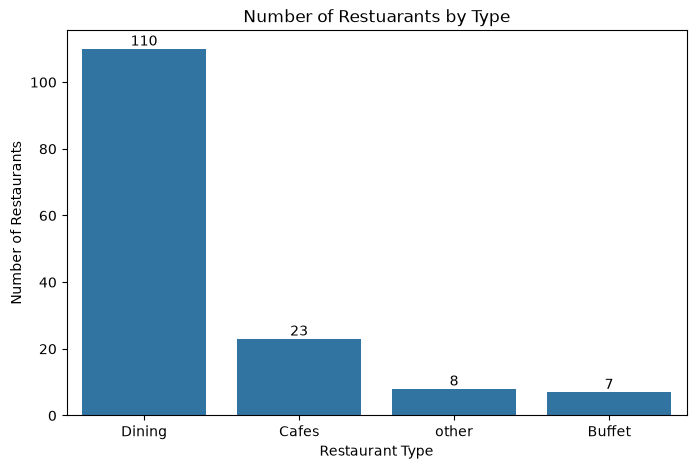

In [106]:
# Number of Restuarants by Type
restaurant_type_counts = eda_df['listed_in(type)'].value_counts()

# First Visualization
plt.figure(figsize=(8,5))
sns.barplot(
    x = restaurant_type_counts.index,
    y = restaurant_type_counts.values
)

for i, value in enumerate(restaurant_type_counts.values):
    plt.text(i, value, str(value), ha='center', va='bottom')
    
plt.title('Number of Restuarants by Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Restaurants')

plt.show()

### Insight

Dining restaurants are the most common restaurant type in the dataset, followed by cafes, other restaurant types, and buffets. This indicates that dining restaurants represent the largest category among the restaurants analyzed.

## 2) Which Restaurant Type Gets the Most Votes?

Text(0, 0.5, 'Total Votes')

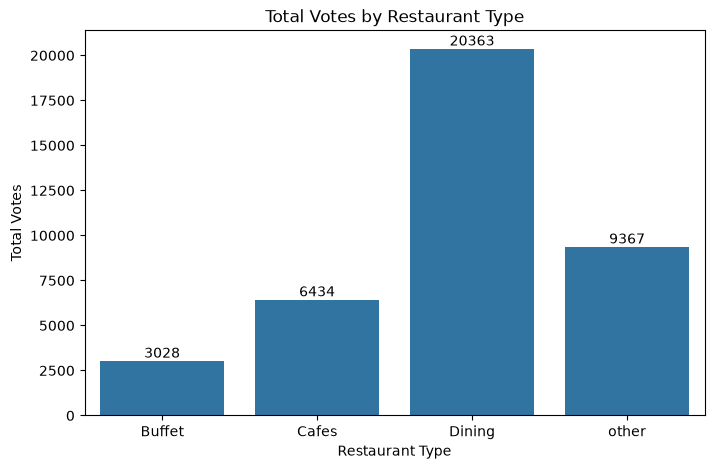

In [107]:
# Total Customer Votes by Restaurant Type
votes_by_type = eda_df.groupby('listed_in(type)')['votes'].sum()

plt.figure(figsize=(8,5))

sns.barplot(
    x=votes_by_type.index,
    y=votes_by_type.values
)

for i, value in enumerate( votes_by_type.values):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.title('Total Votes by Restaurant Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Total Votes')

In [108]:
votes_by_type.idxmax()

'Dining'

In [109]:
print(votes_by_type.max())

20363


### Insight

Dining restaurants received the highest total number of customer votes, with 20,363 votes. This indicates that dining restaurants have the highest level of customer engagement among the restaurant types in this dataset.

## 3) How many restaurants provide online ordering?

Text(0, 0.5, 'Number of Restaurants')

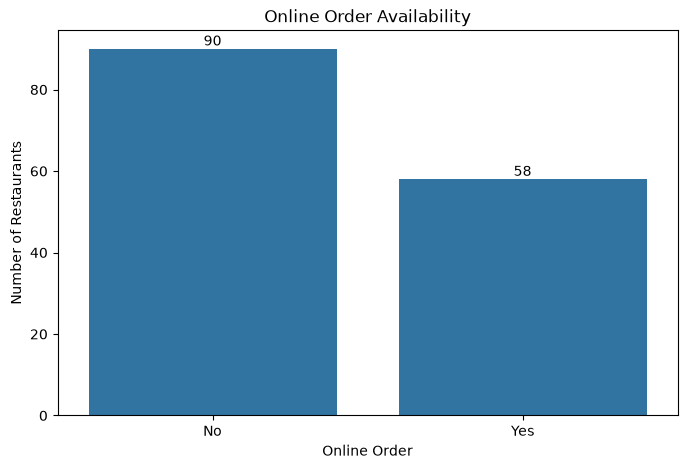

In [110]:
# Online Order Availability
online_order_counts = eda_df['online_order'].value_counts()

plt.figure(figsize=(8,5))

sns.barplot(
    x=online_order_counts.index,
    y=online_order_counts.values
)

for i, value in enumerate(online_order_counts.values):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.title('Online Order Availability')
plt.xlabel('Online Order')
plt.ylabel('Number of Restaurants')

In [111]:
# How much percentage of online vs offline
online_order_percentage = (
    online_order_counts / len(eda_df) * 100
)

online_order_percentage

online_order
No     60.810811
Yes    39.189189
Name: count, dtype: float64

### Insight

Out of 148 restaurants, 90 restaurants (approximately 60.8%) do not provide online ordering, while 58 restaurants (approximately 39.2%) provide online ordering. Therefore, offline ordering is more common than online ordering in this dataset.

## 4) What is the distribution of restaurant ratings?

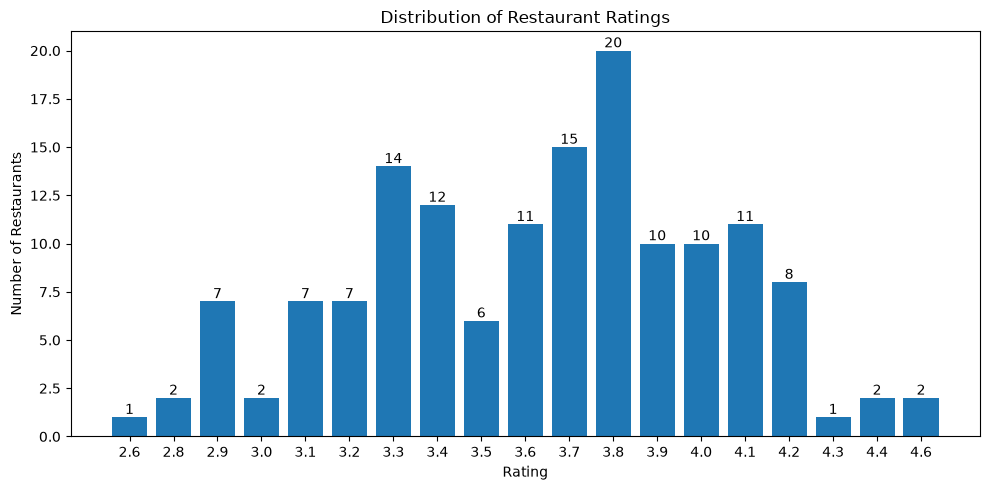

In [112]:
# Rating Analysis

rating_counts = eda_df['rate'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

bars = plt.bar(
    rating_counts.index.astype(str),
    rating_counts.values
)

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        int(height),
        ha='center',
        va='bottom'
    )

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [113]:
# Average Rating
mean = eda_df['rate'].mean()
print(mean)

3.6331081081081082


### Insight

The average restaurant rating is approximately 3.63 out of 5. This indicates that the restaurants in the dataset generally have moderate to good customer ratings, with most ratings concentrated between 3.5 and 4.2.

## 5) What price range is most common for two people?

In [114]:
cost_counts = eda_df['approx_cost(for two people)'].value_counts().sort_index()

cost_counts

approx_cost(for two people)
100     6
150    16
200    16
250     6
300    23
350     3
400    15
450     6
500    14
550     3
600    13
650     2
700     5
750     3
800    12
850     2
900     2
950     1
Name: count, dtype: int64

In [115]:
# Find the most common price
cost_counts.idxmax()

np.int64(300)

In [116]:
# Find how many restaurants
cost_counts.max()

np.int64(23)

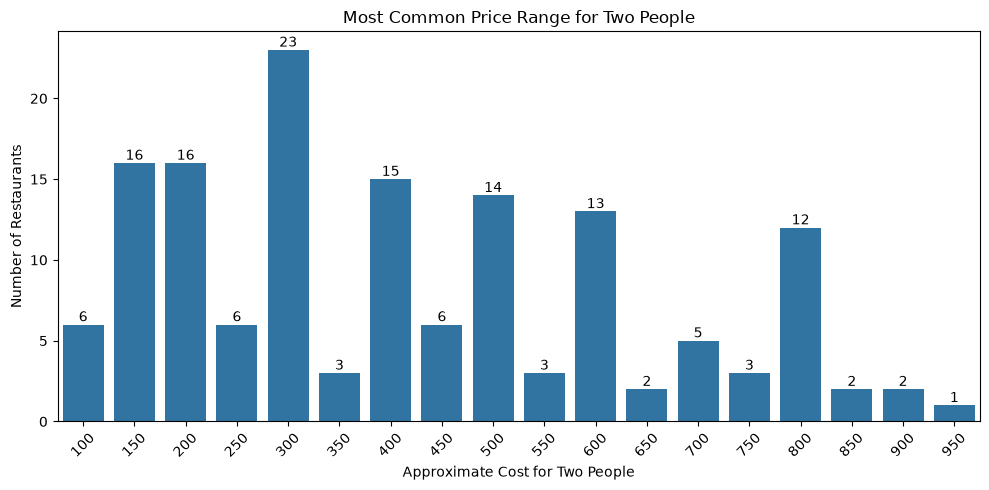

In [117]:
# Approximate Cost for Two People

cost_counts = eda_df['approx_cost(for two people)'].value_counts()

# Sort by cost
cost_counts = cost_counts.sort_index()

plt.figure(figsize=(10,5))

sns.barplot(
    x=cost_counts.index,
    y=cost_counts.values,
    order=cost_counts.index
)

# Add correct data labels
for i, value in enumerate(cost_counts.values):
    plt.text(
        i,
        value,
        str(value),
        ha='center',
        va='bottom'
    )

plt.title('Most Common Price Range for Two People')
plt.xlabel('Approximate Cost for Two People')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Insight
The most common price range for two people is ₹300, with 23 restaurants having this approximate cost. This indicates that ₹300 is the most frequently observed price point in the dataset.

## 6) Do online-order restaurants have better ratings?

In [118]:
# We need to compare the average rating of restaurants that provide online ordering (Yes) vs those that don't (No).
# 1) Calculate average rating for each group
online_rating = eda_df.groupby('online_order')['rate'].mean()
online_rating

online_order
No     3.487778
Yes    3.858621
Name: rate, dtype: float64

In [119]:
online_rating.idxmax()

'Yes'

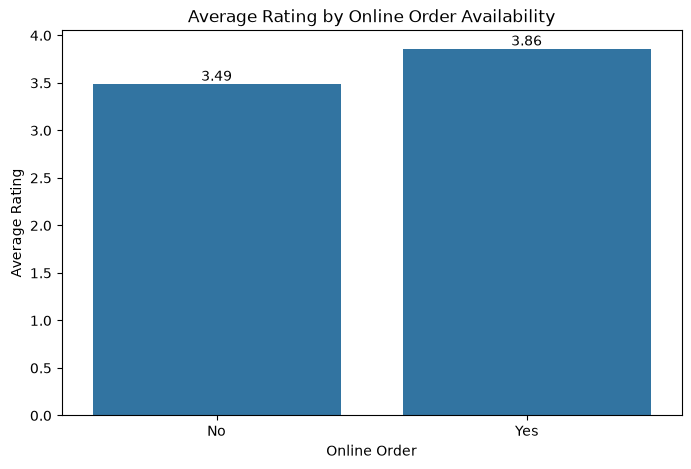

In [120]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=online_rating.index,
    y=online_rating.values
)
for i, value in enumerate(online_rating.values):
    plt.text(i, value, f"{value:.2f}", ha='center', va='bottom')
plt.title('Average Rating by Online Order Availability')
plt.xlabel('Online Order')
plt.ylabel('Average Rating')

plt.show()

### Insight

Restaurants that provide online ordering have a higher average rating of 3.86, compared with 3.49 for restaurants that do not provide online ordering. This shows that, in this dataset, restaurants offering online ordering have higher average ratings.

## 7) Which restaurant type has more online orders?

In [121]:
# Count online orders by restaurant type
online_by_type = eda_df[eda_df['online_order'] == 'Yes'].groupby('listed_in(type)').size()
online_by_type

listed_in(type)
Buffet     4
Cafes     15
Dining    33
other      6
dtype: int64

In [122]:
online_by_type.idxmax()

'Dining'

In [123]:
online_by_type.max()

np.int64(33)

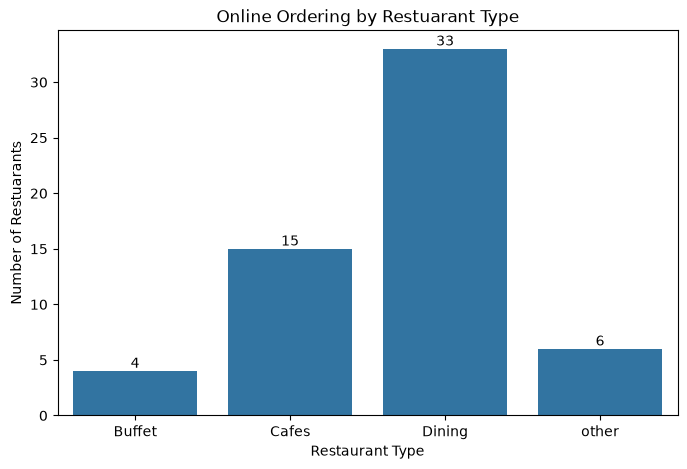

In [124]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=online_by_type.index,
    y=online_by_type.values
)

for i, value in enumerate(online_by_type.values):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.title('Online Ordering by Restuarant Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Number of Restuarants')

plt.show()

### Insight

Dining restaurants have the highest number of restaurants providing online ordering, with 33 restaurants. Cafes follow with 15 restaurants, while other restaurant types and buffets have 6 and 4 restaurants respectively.

## 8) Which restaurants have the highest votes?

In [125]:
# Sort restaurants by votes
top_voted = eda_df[['name', 'votes']].sort_values(
    by='votes',
    ascending=False
)
top_voted.head(10)

,name,votes
38,Empire Restaurant,4884
86,Meghana Foods,4401
7,Onesta,2556
44,Onesta,2556
65,Kabab Magic,1720
37,Szechuan Dragon,1647
54,Roving Feast,1047
2,San Churro Cafe,918
14,San Churro Cafe,918
67,Gustoes Beer House,868


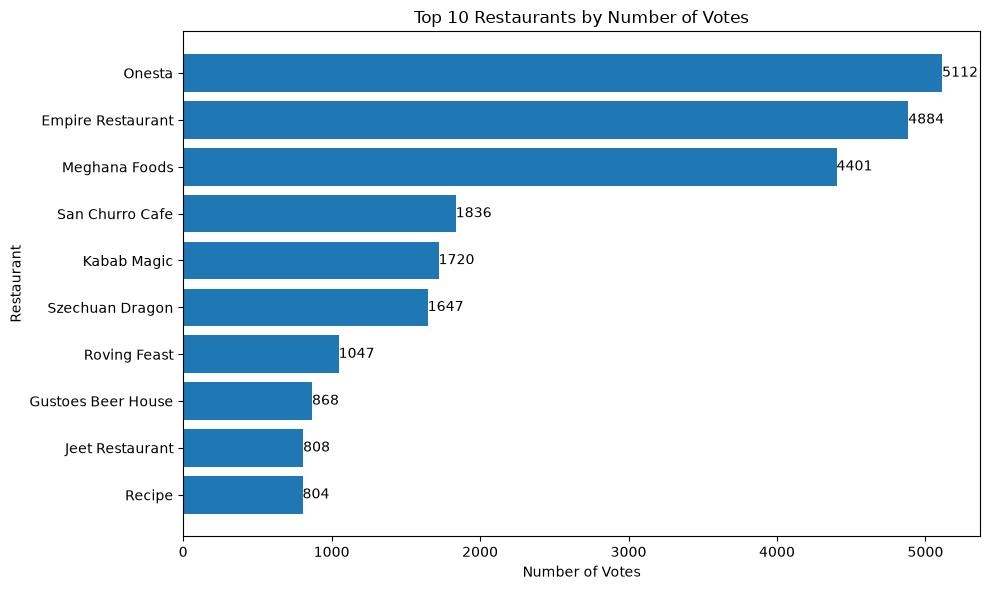

In [126]:
# Top 10 Restaurants by Votes

top_voted = (
    eda_df.groupby('name', as_index=False)['votes']
    .sum()
    .sort_values(by='votes', ascending=False)
)

# Get top 10
top_10_voted = top_voted.head(10)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_voted['name'],
    top_10_voted['votes']
)

# Add data labels
for i, value in enumerate(top_10_voted['votes']):
    plt.text(
        value,
        i,
        str(value),
        va='center'
    )

plt.title('Top 10 Restaurants by Number of Votes')
plt.xlabel('Number of Votes')
plt.ylabel('Restaurant')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Insight

Onesta has the highest number of votes in the dataset, with 5,112 votes across its listings, followed by Empire Restaurant with 4,884 and Meghana Foods with 4,401. This indicates that these restaurants have received the highest level of customer engagement among the restaurants analyzed.

## 9) What are the most popular restaurant types based on customer engagement?

In [129]:
# Calculate total votes by restaurant type
engagement_by_type = eda_df.groupby('listed_in(type)')['votes'].sum()
engagement_by_type

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

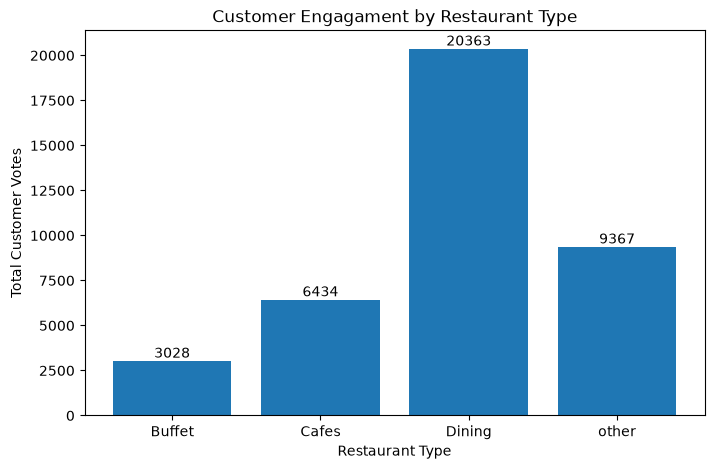

In [130]:
plt.figure(figsize=(8,5))

plt.bar(
    engagement_by_type.index,
    engagement_by_type.values
)

for i, value in enumerate(engagement_by_type.values):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.title('Customer Engagament by Restaurant Type')
plt.xlabel('Restaurant Type')
plt.ylabel('Total Customer Votes')

plt.show()

### Insight:
Dining restaurants have the highest customer engagement with 20,363 total votes, followed by other restaurant types with 9,367 votes, cafes with 6,434 votes, and buffets with 3,028 votes. This shows that dining restaurants received the highest level of customer engagement in the dataset.